setup and class names

In [10]:
from pathlib import Path
from collections import Counter
import yaml
import matplotlib.pyplot as plt
import cv2, random

ROOT = Path("..") / "data" / "ppe"
cfg = yaml.safe_load(open(ROOT / "data.yaml"))
names = cfg["names"]
if isinstance(names, dict):
    names = [names[i] for i in sorted(names)]
print("Number of classes:", len(names))
for i, n in enumerate(names):
    print(i, n)

Number of classes: 10
0 -
1 - annotate- and create datasets
2 - collaborate with your team on computer vision projects
3 - collect - organize images
4 - export- train- and deploy computer vision models
5 - understand and search unstructured image data
6 - use active learning to improve your dataset over time
7 Construction Site Safety - v28 YOLOv5s
8 Roboflow is an end-to-end computer vision platform that helps you
9 This dataset was exported via roboflow.com on February 1- 2023 at 4-08 PM GMT


In [11]:
import yaml

NAMES = {0: "Mask", 1: "Safety-Vest", 2: "No-Safety-Vest", 3: "Person", 4: "machinery",
         5: "Safety-Cone", 6: "vehicle", 7: "Hardhat", 8: "No-Mask", 9: "No-Hardhat"}
names = [NAMES[i] for i in range(10)]

fixed = {"path": str(ROOT.resolve()), "train": "train/images", "val": "valid/images",
         "test": "test/images", "nc": 10, "names": NAMES}
with open(ROOT / "data_fixed.yaml", "w") as f:
    yaml.safe_dump(fixed, f, sort_keys=False)
print(open(ROOT / "data_fixed.yaml").read())

path: E:\ppe-safety-detector\data\ppe
train: train/images
val: valid/images
test: test/images
nc: 10
names:
  0: Mask
  1: Safety-Vest
  2: No-Safety-Vest
  3: Person
  4: machinery
  5: Safety-Cone
  6: vehicle
  7: Hardhat
  8: No-Mask
  9: No-Hardhat



image and label counts per split

In [12]:
for split in ["train", "valid", "test"]:
    imgs = list((ROOT / split / "images").glob("*"))
    lbls = list((ROOT / split / "labels").glob("*.txt"))
    empty = sum(1 for f in lbls if f.stat().st_size == 0)
    print(f"{split:6s} images={len(imgs):5d} labels={len(lbls):5d} empty_labels={empty}")

train  images= 5518 labels= 5518 empty_labels=0
valid  images=  555 labels=  555 empty_labels=0
test   images=  278 labels=  278 empty_labels=0


class balance per split

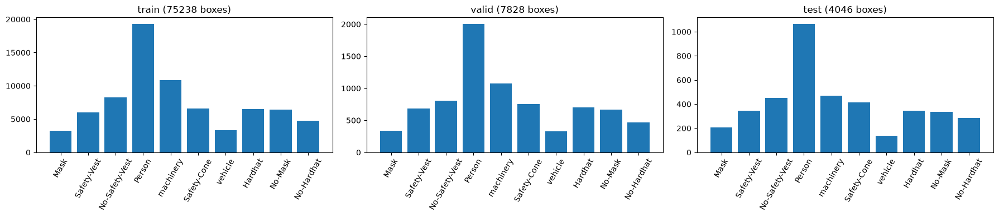

In [13]:
def count_classes(split):
    c = Counter()
    for f in (ROOT / split / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                c[int(line.split()[0])] += 1
    return c

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, split in zip(axes, ["train", "valid", "test"]):
    c = count_classes(split)
    ax.bar([names[i] for i in sorted(c)], [c[i] for i in sorted(c)])
    ax.set_title(f"{split} ({sum(c.values())} boxes)")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig("../outputs/class_balance.png", dpi=120)
plt.show()

draw labels on random images

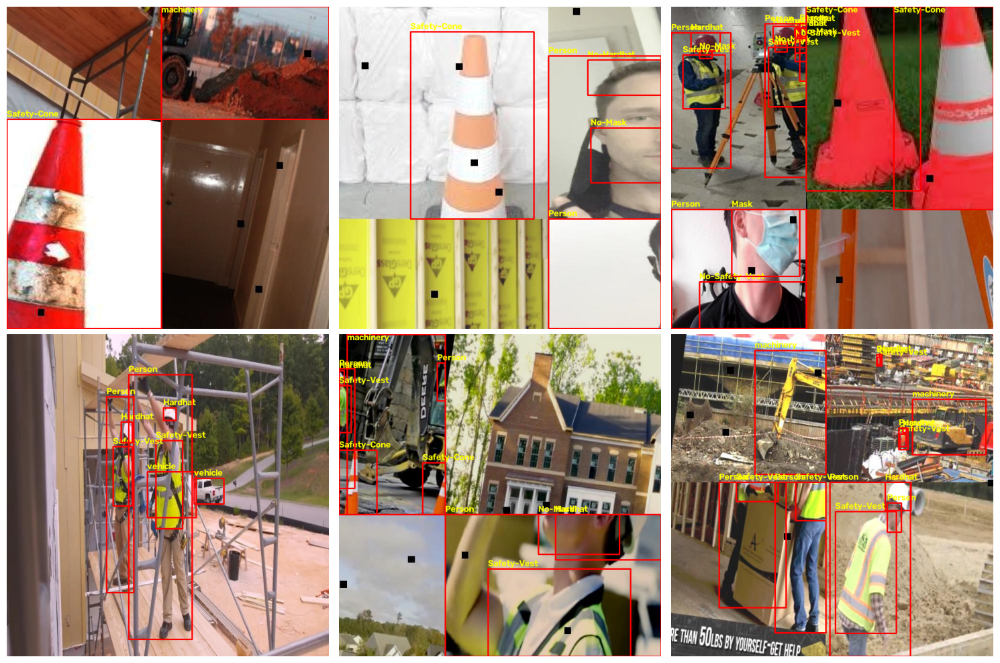

In [14]:
def show_samples(split, n=6):
    imgs = random.sample(list((ROOT / split / "images").glob("*")), n)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for ax, p in zip(axes.ravel(), imgs):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        lbl = ROOT / split / "labels" / (p.stem + ".txt")
        for line in lbl.read_text().splitlines():
            cls, cx, cy, bw, bh = line.split()[:5]
            cx, cy, bw, bh = float(cx)*w, float(cy)*h, float(bw)*w, float(bh)*h
            x1, y1, x2, y2 = int(cx-bw/2), int(cy-bh/2), int(cx+bw/2), int(cy+bh/2)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(img, names[int(cls)], (x1, max(y1-5, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
        ax.imshow(img); ax.axis("off")
    plt.tight_layout(); plt.show()

show_samples("valid")

collect boxes per class

In [15]:
from pathlib import Path
from collections import defaultdict
import cv2, random
import matplotlib.pyplot as plt

ROOT = Path("..") / "data" / "ppe"
random.seed(0)

boxes = defaultdict(list)
for f in (ROOT / "train" / "labels").glob("*.txt"):
    for line in f.read_text().splitlines():
        p = line.split()
        if len(p) >= 5:
            boxes[int(p[0])].append((f.stem, *map(float, p[1:5])))

print("class_id  count  avg_width  avg_height")
for c in sorted(boxes):
    b = boxes[c]
    print(f"{c:8d} {len(b):6d} {sum(x[3] for x in b)/len(b):10.3f} {sum(x[4] for x in b)/len(b):10.3f}")

class_id  count  avg_width  avg_height
       0   3257      0.231      0.224
       1   6034      0.133      0.140
       2   8241      0.192      0.194
       3  19316      0.270      0.282
       4  10823      0.344      0.347
       5   6615      0.058      0.063
       6   3309      0.167      0.169
       7   6493      0.077      0.078
       8   6409      0.057      0.057
       9   4741      0.133      0.125


show cropped examples of every class id

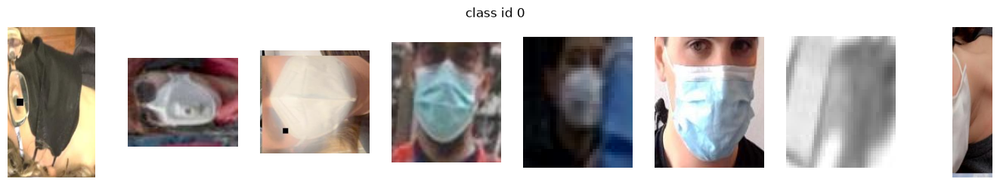

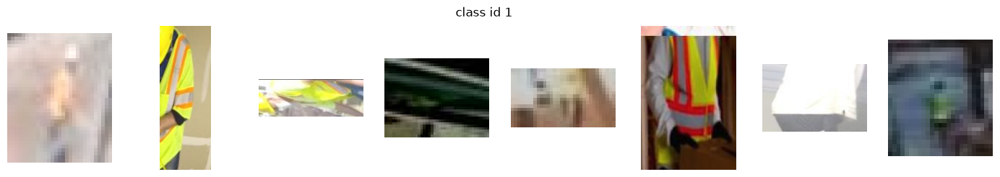

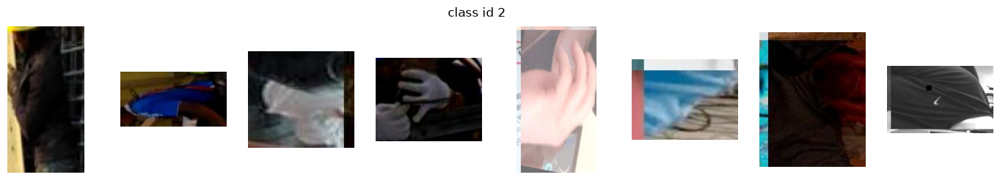

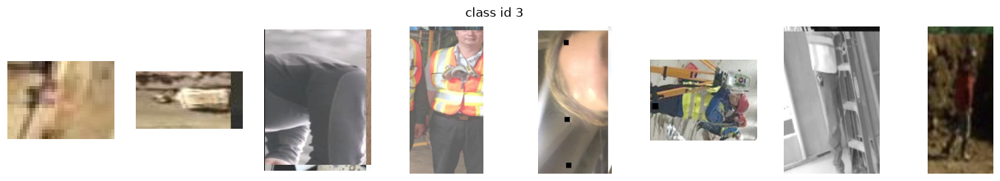

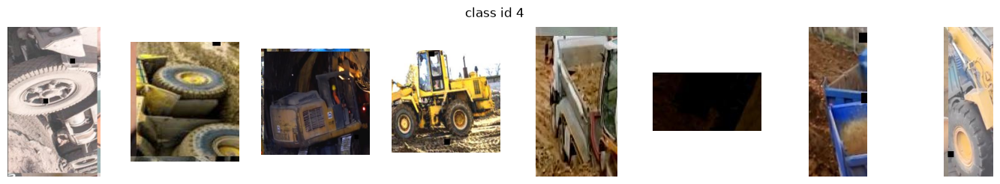

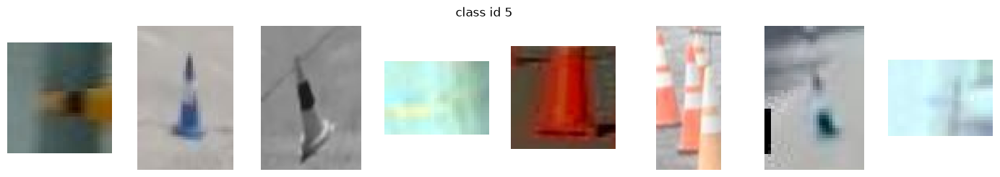

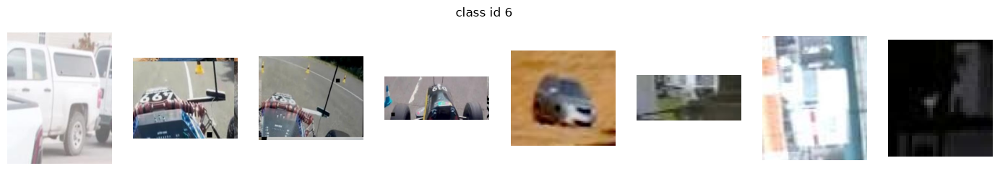

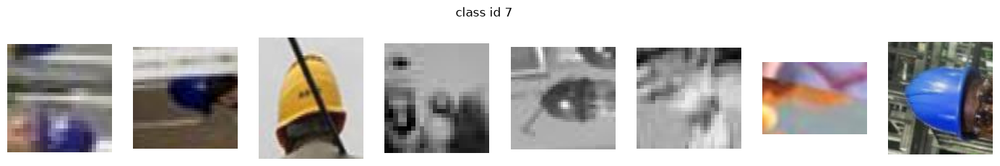

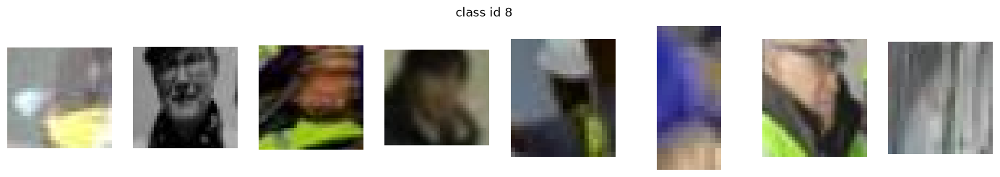

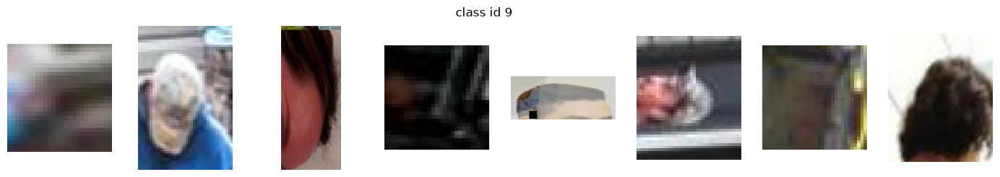

In [16]:
def find_img(stem):
    for ext in (".jpg", ".jpeg", ".png"):
        p = ROOT / "train" / "images" / (stem + ext)
        if p.exists():
            return p

def show_class(c, n=8):
    picks = random.sample(boxes[c], min(n, len(boxes[c])))
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 2.6))
    for ax in axes:
        ax.axis("off")
    for ax, (stem, cx, cy, bw, bh) in zip(axes, picks):
        img = cv2.cvtColor(cv2.imread(str(find_img(stem))), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        x1 = max(int((cx - bw / 2) * w) - 10, 0)
        y1 = max(int((cy - bh / 2) * h) - 10, 0)
        x2 = min(int((cx + bw / 2) * w) + 10, w)
        y2 = min(int((cy + bh / 2) * h) + 10, h)
        ax.imshow(img[y1:y2, x1:x2])
    fig.suptitle(f"class id {c}")
    plt.show()

for c in sorted(boxes):
    show_class(c)

candidate images: 429


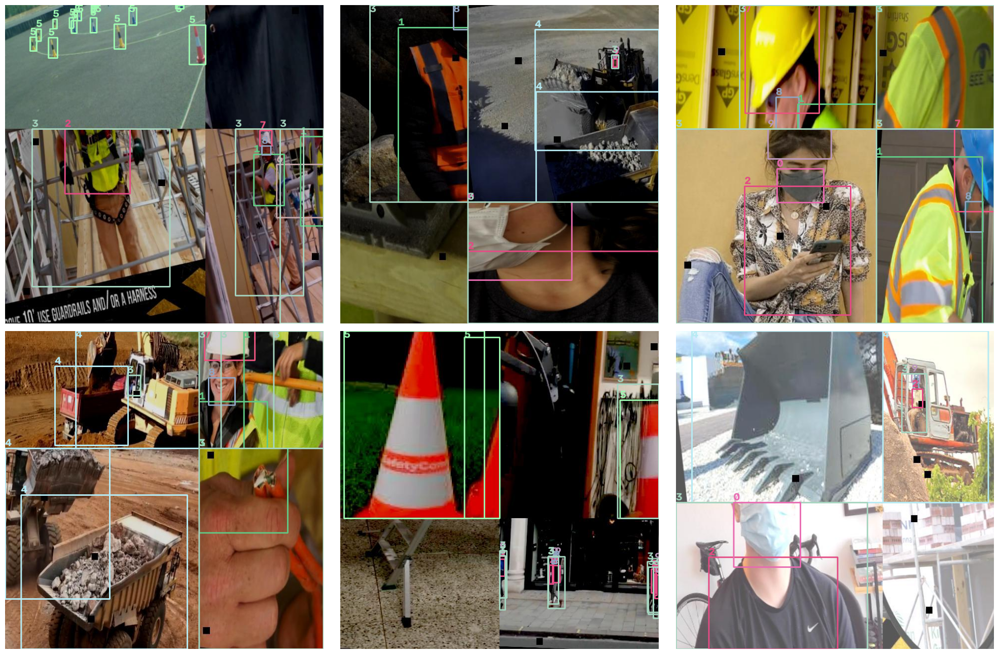

In [17]:
import numpy as np

random.seed(1)
want = {1, 2, 3, 8, 9}
cands = []
for f in (ROOT / "valid" / "labels").glob("*.txt"):
    ids = {int(l.split()[0]) for l in f.read_text().splitlines() if l.strip()}
    if len(ids & want) >= 3:
        cands.append(f)
print("candidate images:", len(cands))

colors = {i: tuple(int(x) for x in np.random.RandomState(i).randint(60, 255, 3)) for i in range(10)}

def find_valid_img(stem):
    for ext in (".jpg", ".jpeg", ".png"):
        p = ROOT / "valid" / "images" / (stem + ext)
        if p.exists():
            return p

fig, axes = plt.subplots(2, 3, figsize=(20, 13))
for ax, f in zip(axes.ravel(), random.sample(cands, 6)):
    img = cv2.cvtColor(cv2.imread(str(find_valid_img(f.stem))), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in f.read_text().splitlines():
        c, cx, cy, bw, bh = line.split()[:5]
        c = int(c)
        cx, cy, bw, bh = float(cx)*w, float(cy)*h, float(bw)*w, float(bh)*h
        x1, y1, x2, y2 = int(cx-bw/2), int(cy-bh/2), int(cx+bw/2), int(cy+bh/2)
        cv2.rectangle(img, (x1, y1), (x2, y2), colors[c], 2)
        cv2.putText(img, str(c), (x1, max(y1-4, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, colors[c], 2)
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()

images with both 7 and 9: 126


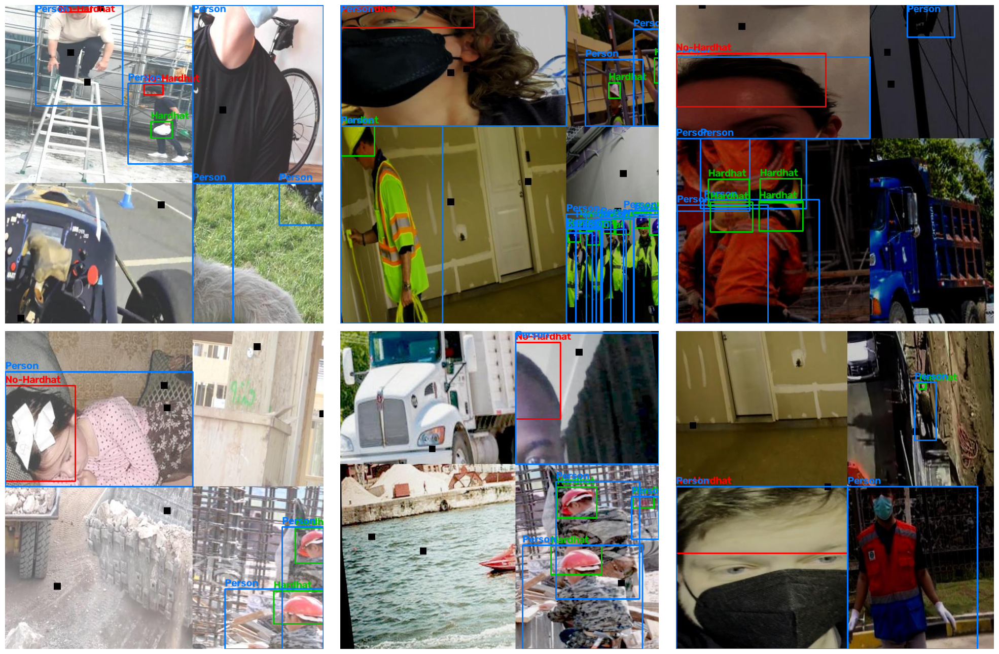

In [18]:
random.seed(3)
cands9 = [f for f in (ROOT / "valid" / "labels").glob("*.txt")
          if any(l.split()[0] == "9" for l in f.read_text().splitlines() if l.strip())
          and any(l.split()[0] == "7" for l in f.read_text().splitlines() if l.strip())]
print("images with both 7 and 9:", len(cands9))

show = {7: ("Hardhat", (0, 200, 0)), 9: ("No-Hardhat", (255, 0, 0)), 3: ("Person", (0, 120, 255))}
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
for ax, f in zip(axes.ravel(), random.sample(cands9, min(6, len(cands9)))):
    img = cv2.cvtColor(cv2.imread(str(find_valid_img(f.stem))), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in f.read_text().splitlines():
        c, cx, cy, bw, bh = line.split()[:5]
        c = int(c)
        if c not in show:
            continue
        cx, cy, bw, bh = float(cx)*w, float(cy)*h, float(bw)*w, float(bh)*h
        x1, y1, x2, y2 = int(cx-bw/2), int(cy-bh/2), int(cx+bw/2), int(cy+bh/2)
        cv2.rectangle(img, (x1, y1), (x2, y2), show[c][1], 2)
        cv2.putText(img, show[c][0], (x1, max(y1-5, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, show[c][1], 2)
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()